# Introduction

The tutorial sessions during the first day are aimed at introducing the students and new researchers in the field about basic notions on atomic and electronic structure of twisted bilayer graphene. 

To achieve this, we will first focus our attention to single layer graphene, followed by AB-stacked bilayer graphene as well as graphite and then conclude with twisted bilayer graphene where will teach the basics of building a commensurate angle for a chosen twist angle and then use this structure to calculate the electronic band structure and density of states. As a bonus, we provide the reader with a session focused on graphene on hBN.

For this session, we will be using our in-house code called [GRABNES](https://scqc.uos.ac.kr/grabnes/), but note that several other real-space tight-binding packages exist, including some that are written and maintained by other participants to this workshop. Each package has its own strengths, so one may be more suitable than another one for the calculation of specific observables. Check for instance (in alphabetical order):

- [Kwant](https://kwant-project.org/)
- [PyBinding](https://docs.pybinding.site/en/stable/)
- [PythTB](http://www.physics.rutgers.edu/pythtb/#)
- [Quantum-Kite](https://quantum-kite.com/)
- [TBPLaS](http://www.tbplas.net/)
- [Twister](https://github.com/qtm-iisc/Twister)


The input files for the GRABNES code will be generated within this python Jupyter notebook, while the calculations themselves will be running in the background using Fortran. We use the [PyToGrabnes](./PyToGrabnes.py) library written for this purpose. For production work, we recommend compiling the code on your own computational resources to leverage the OMP capabilities of the code.

# Library imports and prerequisites

Shared resources:

- [Intel compilers](https://drive.google.com/drive/folders/1Tibs8CyhK1N1DwWwtZn30Jeo_zZ3NN8Y?usp=sharing) (mandatory). After clicking this link which will bring you to the google drive, click on "Shared with me". You should see a folder called `intel` there. Right click this folder and then click on `add shortcut to drive`. This will create a link to your home folder on google drive and this shared folder will be visible to this notebook.  
- [Google colab version of current page](https://colab.research.google.com/drive/12_ofrjJi4pr6U9j-ER1WocYJkqxEffs-?usp=sharing) (mandatory). You can keep a tab open with the current version for reference purposes, but to be able to run the calculations, you need to run this notebook in Google Colab.  
- [Folder with input files, structures, etc for this tutorial](https://drive.google.com/drive/folders/1RshcDiu7zTN9RJKy3u2bet-1Sv3Rw_J4?usp=sharing).  After clicking this link which will bring you to the google drive, click on "Shared with me". You should see a folder called `intel` there. Right click this folder and then click on `add shortcut to drive`. This will create a link to your home folder on google drive and this shared folder will be visible to this notebook.  
- [grabnes source code](https://drive.google.com/drive/folders/1NTrGNbXjJWM-U-F2btPHIxy2EZVLK-Dk?usp=sharing) (optional).  

After performing the 3 (or 4) bullet points above, you need to first run the next few cells to link your google drive to this google colab notebook. This can be done by running the following few cells.

In [ ]:
from google.colab import drive
drive.mount('/drive')

Drive already mounted at /drive; to attempt to forcibly remount, call drive.mount("/drive", force_remount=True).


In [ ]:
import os

rootDirRef = "/drive/MyDrive/Twistronics2023/"
rootDir = "/drive/MyDrive/Twistronics2023_personal/"

os.chdir(rootDir + "scripts/")

import PyToGrabnes as pg
import matplotlib.pyplot as plt
import os
import numpy as np

from IPython.display import Image
from IPython.core.display import HTML 

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
#!chmod -R 777 /drive/MyDrive/lanczosKuboCode/ # Change permissions so you can run the fortran code
#!chmod -R 777 /drive/MyDrive/Twistronics2023/scripts/ # Change permissions so you can run the fortran code
!chmod -R 777 //drive/MyDrive/Twistronics2023/code/

In [ ]:
!source /drive/MyDrive/intel/oneapi/setvars.sh

 
:: initializing oneAPI environment ...
   bash: BASH_VERSION = 4.4.20(1)-release
   args: Using "$@" for setvars.sh arguments: 
:: ccl -- latest
:: compiler -- latest
:: debugger -- latest
:: dev-utilities -- latest
:: dpcpp-ct -- latest
:: dpl -- latest
:: mkl -- latest
:: mpi -- latest
:: tbb -- latest
:: oneAPI environment initialized ::
 


# Graphene

## Introduction

Graphene is probably the most famous two-dimensional allotrope within the carbon material family. The carbon atoms form a 2D sheet of atoms organized in a honeycomb pattern. From a crystallographic perspective, this system can be represented using a unit cell containing two atoms provided the unit vectors are chosen appropriately. This is illustrated in the following figure.

[autoreload of PyToGrabnes failed: Traceback (most recent call last):
  File "/usr/local/lib/python3.8/dist-packages/IPython/extensions/autoreload.py", line 245, in check
    superreload(m, reload, self.old_objects)
  File "/usr/local/lib/python3.8/dist-packages/IPython/extensions/autoreload.py", line 394, in superreload
    module = reload(module)
  File "/usr/lib/python3.8/imp.py", line 314, in reload
    return importlib.reload(module)
  File "/usr/lib/python3.8/importlib/__init__.py", line 168, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'PyToGrabnes'
]


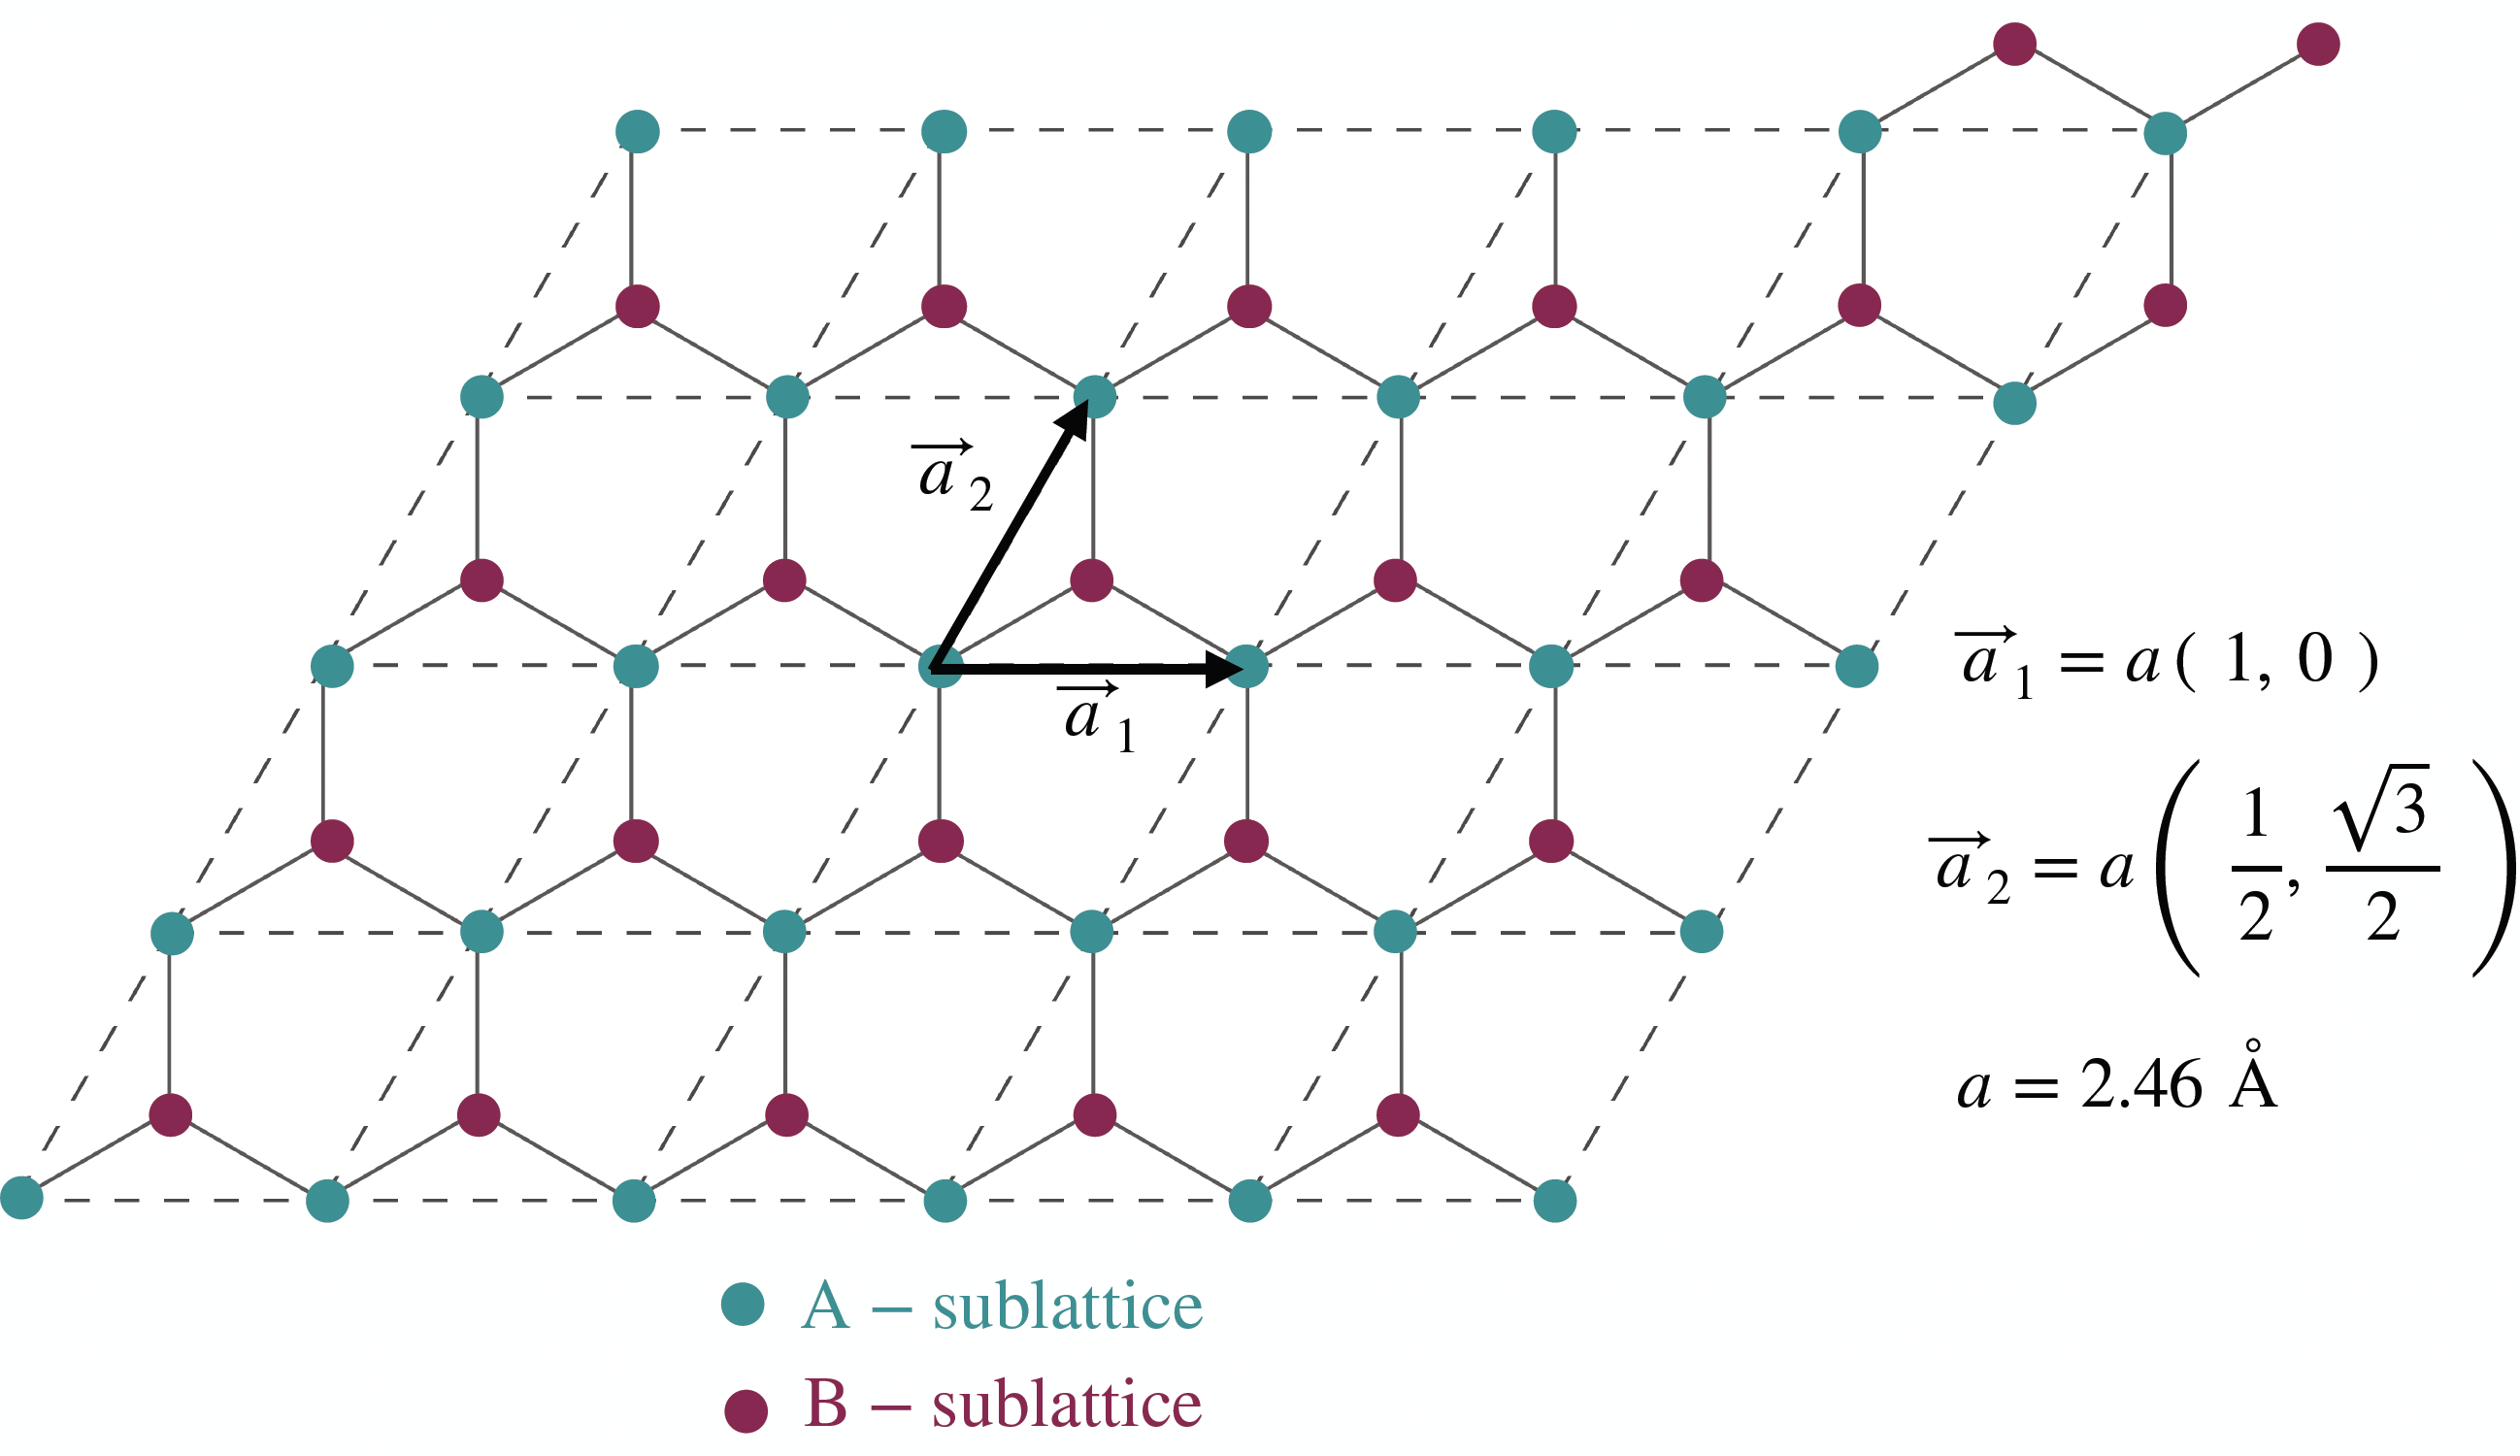

In [ ]:
os.chdir(rootDir)
Image(filename = "./figures/grapheneUnitCell.png",width=600)

The two carbon atoms forming the unit cell are commonly referred to as the A and B sublattice atoms. In pristine graphene, they are equivalent, while when applying a mass-term, they can become inequivalent. In the former case, pristine graphene behaves as a semi-metal while in the latter, one can induce a gap opening in the system.

For this first exercise, we are going to introduce a bandgap in the system by introducing such a mass term.

This exercise will be your first experience in using the grabnes code. Several complexities are hidden away but you are stronlgy encouraged to ask questions or investigate on your own in the source code to understand what is happening under the hood.

## Building the system

For this session, we are simply going to use the in-built methods to build the graphene system. These methods can be used to quickly build rigid structures of graphene and twisted bilayer graphene. The following input file builds the structure and the Hamiltonian, but does not calculate any observable. As a power-user, you'd be compiling the Fortran code on your own computer cluster and you'd be editing the input file using your favorite terminal editor. We won't do that today.

One important thing to note is that the input file, here called `Gendata.in`, is not read sequentially by the code, _i.e._ the order in which you provide the input flags does not matter. The usual format shows the name of the flag followed by it's value (a numerical value, a boolean `.false.` or `.true.`, strings or code blocks). Please note that the parser requires negative values to be given as `0.0-1.0` instead of `-1.0`.

In [ ]:
import os
os.chdir(rootDir)

fileName = "Gendata.in"
#workingDir = rootDir + "graphene/"
#os.mkdir(workingDir)
workingDir = rootDir + "graphene/structure/"
#os.mkdir(workingDir)
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                     "CellSize 10", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction 
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false." # Electronic band structure calculation
                            "Calculate.DOS .false." # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_output = ["WriteDataFiles .true.", # Write the Hamiltonian files
                       "WritePos .true.", # Write the structure files
                      ]     

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_output)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

Tasks:

- [ ] Build the structure by running the code. 
- [ ] Vizualize the structure using the `plotStructure()` method. 
- [ ] Add the lattice vectors to the system using the `plotLatticeVectors()` method.   

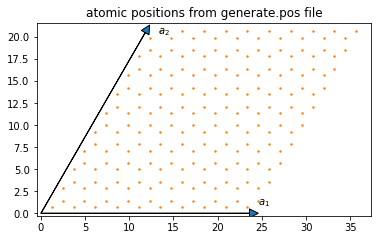

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.plotStructure("generate.pos")
pg.plotLatticeVectors()

If the code ran correctly, you should see a graphene structure where the original graphene unit cell has been repeated `n` times in the direction of the $a_1$ and $a_2$ vectors as defined by the `CellSize` flag in the input file. Note that the `SuperCell` flag allows to repeat the cell defined by the cell size `m` times, thus making it easy to repeat moire cells that are larger than the initial graphene cell. This will be illustrated in a future section on graphene/hBN.

## Electronic structure observables

Her, we are going to obtain a few electronic structure observables by controlling the flags in the `inputStrings_calc` python list above and include the following additional python lists when concatenating `inputStrings`.
- `inputStrings_ham` python list to control the TB model that is used in this calculation.  
- `inputStrings_neigh` python list to control the flags that control which neighbors to include in the TB model.  

To get accurate graphene bandstructures, we are going to use the F2G2 model as proposed in the reference 
[Tight-binding model for graphene $\pi$-bands from maximally localized Wannier functions](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.87.195450). This model requires including up to 5th nearest neighbors.


## Electronic structure

The following code will generate the input file to calculate the electronic bandstructure. We also provide the commands to run, post-process and visualize the corresponding band structure. Please read the Python comments behind the pound keys to understand what each string does.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "graphene/bandstructure/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1",# Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "oneLayer .true." # self explanatory
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100", # Take a large enough value to be able to store sufficient neighbors. A segmentation fault will occur if it is not sufficiently large
                      "TB.NeighLevels 5", # 5 levels are required for the F2G2 models
                      "nonBulkSmall .true.", # Because the system is very small, we must use this less efficient routine to find the neighbors. Most systems work with the default routine though.
                      "Bulk .false."] # Only need to activate it for bulk systems

inputStrings_diag = ["Bands.NumPoints 10", # Number of paths in each segment of the bandstructure
                     "&begin Bands.Path 4", # Number of high symmetry points in the bandstructure path
                     "0.0   0.0  0.0", # Gamma in reduced coordinates
                     "0.5   0.0 0.0", # M in reduced coordinates
                     "2/3   1/3 0.0", # K in reduced coordinates
                     "0.0   0.0  0.0", # Gamma in reduced coordinates
                     "&end Bands.Path" # end this code block
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.07504 ", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC"] # Use this for most models that require F2G2 for intralayer and TC for interlayer interactions

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/graphene/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
2 29


Text(0, 0.5, 'E (eV)')

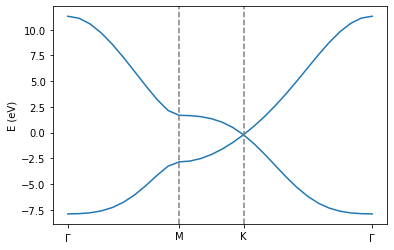

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.5)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
plt.ylabel("E (eV)")

If the code ran correctly, you should see the electronic bandstructure of single layer graphene along the path defined in your input file. This band structure captures the electron-hole asymmetry that is neglected when only including first-nearest neighbor hopping terms. You can check this by re-running the above code snippet, but reducing the value from the `TB.NeighLevels` flag to 1. The current F2G2 model has been optimized so as to capture accurately the low energy states from DFT calculations while limiting the range of the model.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "graphene/bandstructure/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1",# Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "oneLayer .true." # self explanatory
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100", # Take a large enough value to be able to store sufficient neighbors. A segmentation fault will occur if it is not sufficiently large
                      "TB.NeighLevels 1", # 5 levels are required for the F2G2 models
                      "nonBulkSmall .true.", # Because the system is very small, we must use this less efficient routine to find the neighbors. Most systems work with the default routine though.
                      "Bulk .false."] # Only need to activate it for bulk systems

inputStrings_diag = ["Bands.NumPoints 10", # Number of paths in each segment of the bandstructure
                     "&begin Bands.Path 4", # Number of high symmetry points in the bandstructure path
                     "0.0   0.0  0.0", # Gamma in reduced coordinates
                     "0.5   0.0 0.0", # M in reduced coordinates
                     "2/3   1/3 0.0", # K in reduced coordinates
                     "0.0   0.0  0.0", # Gamma in reduced coordinates
                     "&end Bands.Path" # end this code block
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.07504 ", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC"] # Use this for most models that require F2G2 for intralayer and TC for interlayer interactions

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/graphene/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
2 29


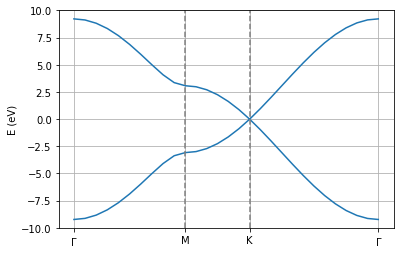

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.5)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
plt.ylabel("E (eV)")
plt.ylim(-10,10)
plt.grid()

## Density of states

We are now going to modify the input file to calculate the density of states for this system. This can be done using Lanczos recursion or exact diagonalisation. Lanczos recursion is based on the idea of tridiagonalizing the original Hamiltonian $H$ into a smaller Hamiltonian $\hat{H}$ where the operator $\delta(E-\hat{H})$ corresponding to the DOS can be efficiently evaluated numerically. We remind the main expression here and refer to [this reference](https://www.sciencedirect.com/science/article/pii/S0370157320304245) for further details. 
$$
\delta(E-\hat{H}) =
\cfrac{1}{E + i \eta - a_1 - \cfrac{b_1^2}{\dots \cfrac{b_2^2}{\dots \cfrac{\dots}{E+ i \eta - a_{N-1} - \cfrac{b_{N-1}^2}{{E+i \eta - a_N - b_N^2 \times Term}}}}}} 
$$
where $a_N$ are the diagonal recursion coefficients and $b_N$ are the offdiagonal coefficients in the tridiagonal representation while $\eta$ is a numerical broadening in the Lorentzian basis function $\frac{1}{E+i \eta - \hat{H}}$. We terminate the expression here with Term chosen as 1, but more advanced methods exist in literature. These coefficients can be calculated recursively and thus the computational cost scales with the number of recursion coefficients.

Note that when using Lanczos recursion to calculate the DOS, one needs to consider a large enough supercell to sample enough states in real-space and thus properly populate the DOS. This is similar to the requirement of adding sufficient reciprocal-space k-points when using exact diagonalization to obtain the DOS.

Tasks:
- [ ] Run this calculation for a few different supercell sizes and observe how the bandstructure changes. Note that due to computational limitations of the hardware available on Google Colab, you should limit yourself to a value of `500` for the `CellSize` flag. This corresponds to $2 \times 500 \times 500 = 500000$ atoms.  
- [ ] Calculate this same DOS using exact diagonalization and compare with the previous results.  

In [ ]:
### Lanczos recursion

In [ ]:
fileName = "Gendata.in"
workingDir_500 = rootDir + "graphene/lanczosDOS_500/"
os.makedirs(workingDir_500, exist_ok=True)
os.chdir(workingDir_500)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 300", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "oneLayer .true." # self explanatory
                      # Self-explanatory
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"BulkSmall .true."], # We don't need it this time because we are working on a large system

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.07504 ", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC"] # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model

inputStrings_lanczos = ["EnergyMin 0.0-12.0", # Minimum energy for plotting purposes
                        "EnergyMax 12.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps
inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir_500, inputStrings)

In [ ]:
fileName = "Gendata.in"
workingDir_100 = rootDir + "graphene/lanczosDOS_100/"
os.makedirs(workingDir_100, exist_ok=True)
os.chdir(workingDir_100)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 100", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "oneLayer .true." # self explanatory
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.07504", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC"] # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model

inputStrings_lanczos = ["EnergyMin 0.0-12.0", # Minimum energy for plotting purposes
                        "EnergyMax 12.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps
inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir_100, inputStrings)

In [ ]:
os.chdir(workingDir_100)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

In [ ]:
os.chdir(workingDir_500)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

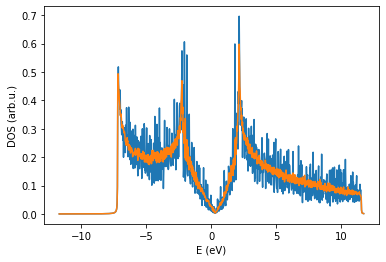

In [ ]:
os.chdir(workingDir_100)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
os.chdir(workingDir_500)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho

If you correctly managed to run the code, you should obtain the DOS for `SuperCell 500` and `SuperCell 100`. The large system gives a much smoother curve for fixed number of recursion steps and energy broadening.

In [ ]:
### Exact diagonalization

Another approach to obtain the DOS is by exact diagonalization. In practice, the choice between Lanczos or exact diagonalization will depend on the system size. The latter is more accurate, but due to poor scaling with system size, one is limited to systems containing `10000` atoms on a low memory machine and `50000` atoms on a high memory machine. The former however can easily deal with systems containing `20 million` atoms on a low memory machine where the precision is controlled by the number of recursion steps that are included in the continued fraction.

For the current small system, both methods can be used so let's also calculate the DOS using exact diagonalization in the next code cell.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "graphene/diagDOS/"
os.makedirs(workingDir, exist_ok=True)
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 10", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "oneLayer .true."
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .true.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_diag = ["KGrid 37 37 1", # Sets the number of k points to include when building the Monckhorst pack
                     "Epsilon 0.1", # Fixes the energy broadening
                     "NumberofEnergyPoints 1000", # Fixes the number of energy points at which to calculate the DOS
                     "DOS.Emin 0.0-15.0",
                     "DOS.Emax 15.0"] 
                     

      

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.07504 ", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC"] # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log


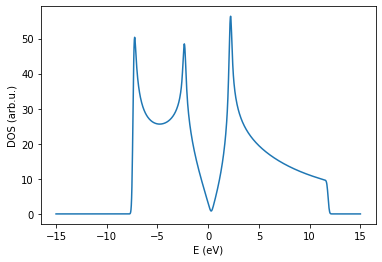

In [ ]:
os.chdir(workingDir)
fileName = "generate.diag.DOS" # update with correct DOS
pg.plotDOS(fileName) # plot the DOS

Both approaches should give similar results for same energy resolution.

Task:

- [ ] Modify the resolution of the DOS by changing the value of `Epsilon`.  
- [ ] Add a gap to this system by using the `addSublatticeMassterm .true.` and `sublatticeMassterm 1.0` flags.




In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "graphene/bandstructure/massterm/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                       "oneLayer .true." # Self-explanatory
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100", # Take a large enough value to be able to store sufficient neighbors. A segmentation fault will occur if it is not sufficiently large
                      "TB.NeighLevels 5", # 5 levels are required for the F2G2 models
                      "nonBulkSmall .true.", # Because the system is very small, we must use this less efficient routine to find the neighbors. Most systems work with the default routine though.
                      "Bulk .false."] # Only need to activate it for bulk systems

inputStrings_diag = ["Bands.NumPoints 50", # Number of paths in each segment of the bandstructure
                     "&begin Bands.Path 4", # Number of high symmetry points in the bandstructure path
                     "0.0   0.0  0.0", # Gamma in reduced coordinates
                     "0.5   0.0 0.0", # M in reduced coordinates
                     "2/3   1/3 0.0", # K in reduced coordinates
                     "0.0   0.0  0.0", # Gamma in reduced coordinates
                     "&end Bands.Path" # end this code block
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.07504 ", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC",
                    "addSublatticeMassterm .true.",
                    "sublatticeMassterm 1.0"
                    ] # Use this for most models that require F2G2 for intralayer and TC for interlayer interactions

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log


<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/graphene/bandstructure/massterm//generate.bands.dat' mode='r' encoding='UTF-8'>
2 138


Text(0, 0.5, 'E (eV)')

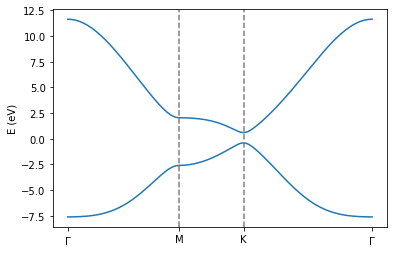

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
plt.ylabel("E (eV)")

# Bernal stacked bilayer graphene: bilayer and bulk graphite

We revisit the skills learnt in the previous section by calculating the electronic band structure for Bernal stacked bilayer graphene and bulk graphite. While doing so, we will introduce a new method to build the system that relies on providing the structural information from external files. This can be particularly useful when reading in relaxed structures from a preliminary LAMMPS calculation for instance.

Up to now, we only had to provide the code with the `Gendata.in` file which contains all the input flags. When using the `ReadXYZ` method, one also has to provide the `generate.xyz` and  `sublatticesSorted.dat` files to inform the code about the position of the atoms and the sublattice to which each of these atom belong. For convenience, we provide these files in the `twistronics2023` folder you downloaded earlier.

## AB-stacked bilayer graphene

In the following figure, we illustrate Bernal stacked bilayer graphene. This is considered to be energetically the most stable configurations when stacking two graphene layers on top of each other. Similarly to the graphene system, this system can be represented using 4 atoms in the unit cell.

Task: 
- [ ] Run the following code cell to obtain the bandstructure. You might need a lot of k-points if you want to capture the fine-features close to the K-point. Because the system is small, it'll still be doable in a reasonable amount of time.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "bilayerGraphene/bandstructure/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem ReadXYZ", # To build graphene using the built-in grabnes methods
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                     "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "twoLayers .true.", # Specify to the code that this is a 2 layer system
                     "twoLayersZ1 1.675", # Specify approximately the z coordinate of the bottom layer
                     "twoLayersZ2 5.025" # Specify approximately the z coordinate of the top layer
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5", # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      "Neigh.LayerDistFactor 1.2", # Not importat
                      "nonBulkSmall .true." # We are not doing a bulk calculation
                      #"BulkSmall .true.",
                      #"Bulk .true."
                      ]

inputStrings_diag = ["Bands.NumPoints 50000",
                     "&begin Bands.Path 4",
                     "0.0   0.0  0.0", # Gamma
                     "0.5   0.0 0.0", # M
                     "2/3   1/3 0.0", # K
                     "0.0   0.0  0.0", # Gamma
                     "&end Bands.Path",
                    ]
                     
                     

      

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC", # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model
                    "forceBilayerF2G2Intralayer .true." # Use the bilayer F2G2 intralayer terms rather than the single layer F2G2 terms
                    ] 


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/bilayerGraphene/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
4 136604


Text(0, 0.5, 'E (eV)')

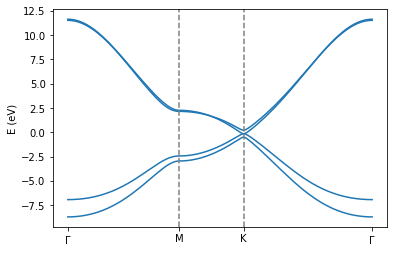

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
#plt.ylim(-0.1446,-0.1438) # Uncomment this to focus on the fine features at the K-point
#plt.xlim(2.32601-0.003,2.32601+0.006) # Uncomment this to focus on the fine features at the K-point
plt.ylabel("E (eV)")

If you correctly ran the calculation, you should see an accurate version of the electronic bandstructure for Bernal stacked graphene. For comparion purposes, see for instance here.

Bonus task: 
- [ ] change the working directory to calculate also the AA stacking electronic bandstructure of bilayer graphene. We provide the `generate.xyz` file in the `bilayerGraphene/bandstructureAA` subfolder.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "bilayerGraphene/bandstructureAA/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem ReadXYZ", # To build graphene using the built-in grabnes methods
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                     "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "twoLayers .true.", # Specify to the code that this is a 2 layer system
                     "twoLayersZ1 1.675", # Specify approximately the z coordinate of the bottom layer
                     "twoLayersZ2 5.025" # Specify approximately the z coordinate of the top layer
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5", # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      "Neigh.LayerDistFactor 1.2", # Not importat
                      "nonBulkSmall .true." # We are not doing a bulk calculation
                      #"BulkSmall .true.",
                      #"Bulk .true."
                      ]

inputStrings_diag = ["Bands.NumPoints 50000",
                     "&begin Bands.Path 4",
                     "0.0   0.0  0.0", # Gamma
                     "0.5   0.0 0.0", # M
                     "2/3   1/3 0.0", # K
                     "0.0   0.0  0.0", # Gamma
                     "&end Bands.Path",
                    ]
                     
                     

      

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC", # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model
                    "forceBilayerF2G2Intralayer .true." # Use the bilayer F2G2 intralayer terms rather than the single layer F2G2 terms
                    ] 


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/bilayerGraphene/bandstructureAA//generate.bands.dat' mode='r' encoding='UTF-8'>
4 136604


Text(0, 0.5, 'E (eV)')

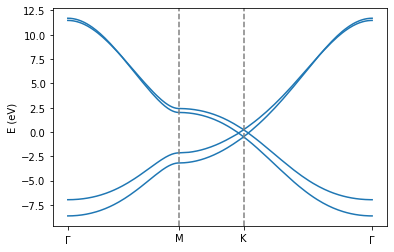

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
plt.axvline(1.474633, linestyle="dashed",color="grey")
plt.axvline(2.326013, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.474633, 2.326013,4.028773],[r"$\Gamma$", "M", "K", r"$\Gamma$"])
#plt.ylim(-0.1446,-0.1438) # Uncomment this to focus on the fine features at the K-point
#plt.xlim(2.32601-0.003,2.32601+0.006) # Uncomment this to focus on the fine features at the K-point
plt.ylabel("E (eV)")

## Graphite

It is straightforward to switch from the previous bilayer calculations by adjusting the structural input file so that interactions between the bottom of the unit cell and the top of the unit cell are taken into account, hence allowing us to calculate the bandstructure for graphite.

Task:
- [ ] Run the following cell. Note the differences between the previous Bernal stacked bilayer calculations and these bulk calculations. 

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "graphite/"
#os.mkdir(workingDir)
workingDir = rootDir + "graphite/bandstructure/"
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem ReadXYZ", # To build graphene using the built-in grabnes methods
                     "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                     "CellSize 1", # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                     "twoLayers .true.", # Specify to the code that this is a 2 layer system
                     "twoLayersZ1 1.675", # Specify approximately the z coordinate of the bottom layer
                     "twoLayersZ2 5.025" # Specify approximately the z coordinate of the top layer
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 50", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 5", # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      "Neigh.LayerDistFactor 1.2", # Not importat
                      "BulkSmall .true.", # We are doing a smnall cell bulk calculation
                      "Bulk .true."  #We are not doing a bulk calculation
                      ]

inputStrings_diag = ["Bands.NumPoints 10",
                     "&begin Bands.Path 8",
                     "0.0   0.0  0.0", # Gamma
                     "1/3   0.0-1/3 0.0", # K
                     "0.5   0.0 0.0", # K
                     "0.0   0.0  0.0", # Gamma
                     "0.0   0.0  0.5",
                     "1/3   0.0-1/3 0.5",
                     "0.5   0.0 0.5",
                     "0.0   0.0  0.5",
                     "&end Bands.Path",
                    ]
                     

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "TypeOfSL HTC", # Hybrid TC model, use it when intralayer interactions follow F2G2 and interlayer follow reparametrized TC model
                    "forceBilayerF2G2Intralayer .true." # Use the bilayer F2G2 intralayer terms rather than the single layer F2G2 terms
                    ] 


inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:

os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/graphite/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
4 52


Text(0, 0.5, 'E (eV)')

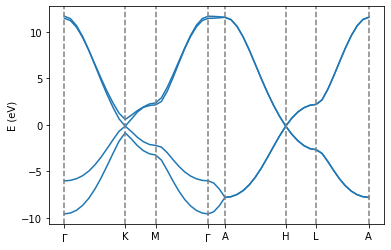

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
#plt.axvline(0.491544*3)
#plt.axvline(0.775337*3
plt.axvline(0.0, linestyle="dashed",color="grey")
plt.axvline(1.702628, linestyle="dashed",color="grey")
plt.axvline(2.553943, linestyle="dashed",color="grey")
plt.axvline(4.028462, linestyle="dashed",color="grey")
plt.axvline(4.497357, linestyle="dashed",color="grey")
plt.axvline(6.199985, linestyle="dashed",color="grey")
plt.axvline(7.051300, linestyle="dashed",color="grey")
plt.axvline(8.525820, linestyle="dashed",color="grey")
plt.xticks([0.0, 1.702628, 2.553943,4.028462,4.497357,6.199985,7.051300,8.525820],[r"$\Gamma$", "K", "M", r"$\Gamma$", "A", "H", "L", "A"])
plt.ylabel("E (eV)")


# Twisted Bilayer Graphene

## Introduction

Twisted bilayer graphene has garnered a lot of attention in recent years due to the interesting properties it displays. When twisting the two layers of graphene at a specific twist angle, the hybridization of the two Dirac cone can lead to the formation of a flat band which can give rise to superconductivity and Mott insulator signatures. To simulate this type of moire system, one needs to build a commensurate cell for each of the twist angles one is interested in. Unlike the untwisted systems, these commensurate cells can be quite large. As a first approximation, the smaller the twist angle, the larger the moire unit cell. Only a discrete set of twist angles exist, but the larger the unit cell, the more angles become accessible.

A versatile way to describe a moire system has been introduced using 4 indices in [this reference](https://iopscience.iop.org/article/10.1088/0953-8984/24/31/314210). We remind the relevant equations here.


The commensurate moire superlattices are fully defined using four integers $i$, $j$, $i^\prime$ and $j^\prime$. Here, let us use $i$ and $j$ for graphene and $i^\prime$ and $j^\prime$ for the other graphene layer. 
The two lattice vectors of the commensurate supercell $\textbf{r}_{1}$, $\textbf{r}_{2}$ 
can be related to the lattice vectors of the bottom layer $\textbf{a}_{1}$, $\textbf{a}_{2}$ and the top layer $\textbf{a}^\prime_{1}$, $\textbf{a}^\prime_{2}$ through
$$
\begin{pmatrix}
\textbf{r}_{1} \\
\textbf{r}_{2}
\end{pmatrix}
= \textbf{M}^{\prime} \cdot
\begin{pmatrix}
\textbf{a}_{1} \\
\textbf{a}_{2}
\end{pmatrix}
= \textbf{M} \cdot
\begin{pmatrix}
\textbf{a}^{\prime}_{1} \\
\textbf{a}^{\prime}_{2} 
\end{pmatrix}
$$
where we use the transformation matrices
$$
\textbf{M} =
\begin{pmatrix}
      i      &     j        \\
    - j      &     i + j
\end{pmatrix}, 
\quad
\textbf{M}^{\prime} =
\begin{pmatrix}
     i^\prime      & j^\prime       \\
    -j^\prime     & i^\prime + j^\prime
\end{pmatrix}.
$$
Defining $a_{G_1}$ and $a_{G_2}$ as the lattice constants of the two constituent layers, we can relate the lattice mismatch ratio $\alpha$ to the four indices as
$$
\alpha = \frac{a_{G_1}}{a_{G_2}} =\sqrt{\frac{(i^\prime{}^2+j^\prime{}^2+i^{\prime}j^\prime)}{i^2+i^2+ij}}
$$
and the rotation angle $\theta$ as
$$
\cos(\theta) = \frac{1}{2 \alpha g}\left[ 2 i^\prime i + 2 j^\prime j + i^\prime j + j^\prime i \right]
$$
where $g=i^2+j^2+ij$. In this case we set $a_{G_1} = a_{G_2}$ to avoid internal strain.

Using these equations will be our first task in the next section where we will build and visualize the moire unit cell.
We then will use this moire unit cell to calculate the density of states using Lanczos recursion.






## Building the commensurate cell

Create a twisted bilayer system using the `31 30 30 31` indices and visualize the structure using the methods given below. You could also download the structure and visualize it using VMD or xCrysDen of course.

The current methods prepare structure output files that can be used as input for a LAMMPS calculation or directly as input for the GRABNES code.

A table with relevant indices is given in [this reference](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.106.115410). 

In [ ]:
!chmod -R 555 /drive/MyDrive/Twistronics2023/tBG/

started
Angle:     3.000000000
Delta:     0.000000000

                a     b     a'    b'       Delta            Angle       N   #1   #2
For angle:      90    53    84    60     0.000541980     2.999897191   43 15679 15696
For delta:      23    21    21    23     0.000000000     3.006558436    4  1453  1453
For both:        0     0     0     0             NaN             NaN    0     0     0

Final angle:     3.006558
Final BN lattice parameter:     2.460190
Atoms for graphene:    2906
Atoms for BN:    2906

Size of layer 1:   1 x 1453   (21 x 23)
Size of layer 2:   1 x 1453   (23 x 21)
 lambda1:   46.889052871787889     
 lambda2:   93.778105743575878     


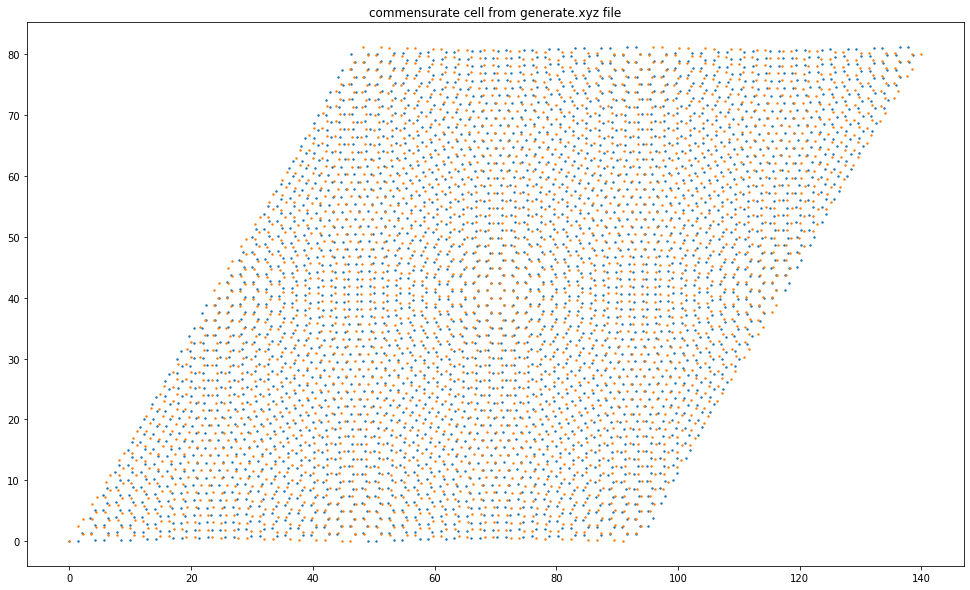

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
workingDir = rootDir + "tBG/"
os.chdir(workingDir)
#pg.prepare_tBG_commensurate_cell_input([31,30,30,31]) # Obtains the commensurate cell using integers
pg.prepare_tBG_commensurate_cell_input(3.0) # Prepares input for fortran code
!/drive/MyDrive/Twistronics2023/tBG/a.out # Runs the fortran executable
pg.prepare_tBG_commensurate_cell_xyz() # Obtains the output in different formats including lammps compatible files
plt.figure(figsize=(20,10))
pg.plotStructure("generate.xyz")
plt.gca().set_aspect("equal")


## Hamiltonian

For the tBG Hamiltonian, we use the SHE model introduced [here](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.106.115410) where the intralayer F2G2 model is the same as the one we used for single layer graphene in the previous session and the interlayer terms are given by a reparametrized and magic angle-renormalized two-center TC approximation model for which we remind the main expression here.
$$
t_{{\rm SHE}, \, ij} = 
\begin{cases} 
t^{{\rm intra}}_{{\rm F2G2}, \, ij} 
& \mbox{if }   i \in \mbox{ layer} j \\ 
S \, \exp\left[ {(c_{ij} - p)}/{q} \right] \, t^{{\rm inter}}_{{\rm TC}, \, ij} & \mbox{if }  i \notin  \mbox{ layer} j
\end{cases}
$$
where $p = 3.25$ Ang and $q = 1.34$ Ang capture the interlayer-dependence of the DFT parametrization and S is a relaxation-dependent renormalization factor which anchors the magic angle at a chosen value. 
This expression contains the [original two-center approximation model](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.86.125413) reminded  as
$$
    t_{ {\rm TC}, \, ij} = V_{pp\pi}(r_{ij}) \left[1 - \left(\frac{ c_{ij} }{r_{ij}} \right)^2 \right] + V_{pp\sigma}(r_{ij}) \left(\frac{ c_{ij} }{r_{ij}} \right)^2
$$
where
$$
    V_{pp\pi}(r_{ij}) = V_{pp\pi}^0 \exp\left(-\frac{r_{ij}-a_{\rm CC}}{r_0}\right)
$$
and
$$
    V_{pp\sigma}(r_{ij}) = V_{pp\sigma}^0 \exp\left(-\frac{r_{ij}-c_0}{r_0}\right),
$$
where $r_{ij} = \left| \textbf{r}_{ij} \right|$ is the magnitude of the interatomic distance 
and $c_{ij} = \textbf{r}_{ij} \cdot \textbf{e}_z$ is the vertical axis projection along the 
$z$-axis normal to the graphene plane. 
For simplicity, here we have defined a fixed normal vector $\textbf{e}_z$ along the $z$-axis 
rather than allowing it to tilt with the local curvature following the surface corrugation. 
The parameter $c_0 = 3.35$ Ang is the interlayer distance, 
$a_\text{CC} = 1.42$ Ang is the rigid graphene's interatomic carbon distance, 
$V_{pp\pi}^0 = -2.7$ eV the transfer integral between nearest-neighbor atoms, 
$V_{pp\sigma}^0 = 0.48$ eV the transfer integral between two vertically aligned atoms
that were fitted to generalized gradient approximation (GGA) data for fixed interlayer distances. The decay length of the transfer integral is chosen as $r_0 = 0.184 a$ such that the next-nearest intralayer coupling becomes 0.1 $V_{pp\sigma}^0$. 
%
The cutoff for this distance-dependent model is finally set to $4.9$ Ang beyond which 
additional contributions do not affect the observables anymore.


## Density of States

### Lanczos DOS

Calculate the Lanczos DOS and optimize the supercell size to get smooth behavior of the curve. Note for the current TB model we have to include a relatively large number of neighbors. bBecause of this, the memory requirements can become quite large. For the sake of this session using Google Colab resources, consider small cells up to `SuperCell 10` for $1.08^\circ$ twist angle. 

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "tBG/"
#os.mkdir(workingDir)
workingDir = rootDir + "tBG/bandstructure/"
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem TwistedBilayerBasedOnMoireCell", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                      # "CellSize 1",
                     "MoireCellParameters 31 30 30 31" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                 #    "MoireCellParameters 11 10 10 11" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100",
                      "TB.NeighLevels 5",
                      "Neigh.LayerDistFactor 4.2",
                      #"nonBulkSmall .true.",
                      #"Bulk .false."
                      ]

inputStrings_diag = ["Bands.NumPoints 10",
                     "&begin Bands.Path 4",
                     " 1/3   0.0-1/3 0.0", # Gamma
                     "0.0   0.0  0.0", # M
                     "0.5   0.0 0.0", # K
                     "1/3   0.0-1/3 0.0", # Gamma
                     "&end Bands.Path"
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.5",
                    "TypeOfBL HTC",
                    "renormalizeCoupling .true.",
                    "couplingFactor 1.008",
                  #  "couplingFactor 2.93",
                    "KoshinoSR .true.",
                    ] # Controls the first nearest neighbor hopping in the F2G2 model

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
#!/drive/MyDrive/lanczosKuboCode/bin/grabnes Gendata.in  #> out.log
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

(0.0, 0.05)

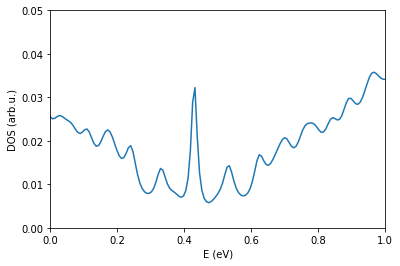

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the meth
plt.xlim(0,1.0)
plt.ylim(0,0.05)

## Electronic band structure

Under normal conditions, it would not be a problem to calculate the electronic bandstructure for this magic angle system. However due to memory and parallelisation limitations inherent to using Google Colab for free, we cannot do this within this session. However, because the TB model that we are using for the interlayer interactions between the two layers of this system can be renormalized using the S factor (see [this reference](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.106.115410) for details), we can obtain by construction a flat band for a larger twist angle which requires a smaller commensurate cell. We remind the formula that can be used to estimate the strength of S for a specific twist angle as

\begin{equation}
\theta_\text{eff} = S \theta_\text{ref}/S^\prime
\end{equation}

where $\theta_\text{ref}$ is the angle of the commensurate cell and $S=0.895$ for structures that are relaxed with the EXX-RPA-fitted force field and $1.008$ for rigid structures at $3.35$ Angstrom interlayer distance. Hence for a rigid system with a twist angle of about $5.08^\circ$, corresponding to indices `7 6 6 7`, we should use a value of $S^\prime = 4.74$.

In [ ]:
Sprime = 1.008*3.14/1.08
print("S' for 3.14 degree:", Sprime)

Sprime = 1.008*3.89/1.08
print("S' for 3.89 degree:", Sprime)

Sprime = 1.008*5.08/1.08
print("S' for 5.08 degree:", Sprime)

S' for 3.14 degree: 2.9306666666666663
S' for 3.89 degree: 3.6306666666666665
S' for 5.08 degree: 4.7413333333333325


### Flat band

Calculate the electronic bandstructure and visualize the flat band.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "tBG/"
#os.mkdir(workingDir)
workingDir = rootDir + "tBG/bandstructure/"
#os.mkdir(workingDir)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem TwistedBilayerBasedOnMoireCell", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 1",
                     "MoireCellParameters 7 6 6 7" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                 #    "MoireCellParameters 11 10 10 11" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .true.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .true.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 100",
                      "TB.NeighLevels 5",
                      "Neigh.LayerDistFactor 4.2",
                      "nonBulkSmall .true.",
                      "Bulk .false."]

inputStrings_diag = ["Bands.NumPoints 10",
                     "&begin Bands.Path 4",
                     " 1/3   0.0-1/3 0.0", # Gamma
                     "0.0   0.0  0.0", # M
                     "0.5   0.0 0.0", # K
                     "1/3   0.0-1/3 0.0", # Gamma
                     "&end Bands.Path"
                     ]

inputStrings_ham = ["TB.OnSiteC 0.4914", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03",
                    "TypeOfBL HTC",
                    "renormalizeCoupling .true.",
                    "couplingFactor 4.7037037", # S'/S
                  #  "couplingFactor 2.93",
                    "KoshinoSR .true.",
                    ] # Controls the first nearest neighbor hopping in the F2G2 model

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_diag
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
#!/drive/MyDrive/lanczosKuboCode/bin/grabnes Gendata.in  > out.log
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

<_io.TextIOWrapper name='/drive/MyDrive/Twistronics2023/tBG/bandstructure//generate.bands.dat' mode='r' encoding='UTF-8'>
508 25


(0.0, 1.5)

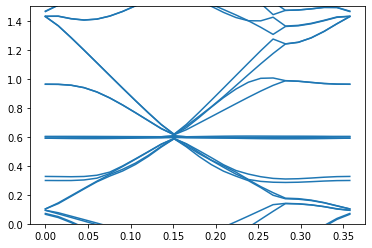

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.transformBands("generate.bands")
pg.plot_electronic_bandstructure(workingDir, 2, 0.2)
#plt.ylim(0.4,0.7)
plt.ylim(0,1.5)
#plt.axvline(0.491544*3)
#plt.axvline(0.775337*3

If you correctly ran the calculation, you should see a flat band occuring in this $5.08^\circ$ simulation cell when increasing the coupling strength using the formula we showed earlier. Please note that we used this formula for illustration purposes so that we can still illustrate flat bands on the single core system that Google Colab provides us with. The larger the difference between the effective angle and the reference angle, the less accurate this approach will become, especially for relaxed systems where the relaxation strength is angle-dependent. Under normal conditions, you would be calculating it for reference angles that are very close to the effective angles. This is realisticably doable on most modern computer clusters in less than 15 minutes in the case of first magic angle of tBG.

# Graphene on h-BN

After spending some time with the standard layered combinations of graphene, we can now turn our attention to graphene on h-BN. For the purpose of this session, we will be using an [effective model extracted from DFT calculations](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.89.205414) which is accurate close to the K-point. This effective model allows to capture and collapse the effect of h-BN in a moire system by simply modifying the onsite energies and hopping terms in a reference graphene layer. We thus reduce computational cost by a factor 2.

We remind the expression for this Hamiltonian here:
$$
H_\text{eff}(\textbf{r})=H_{0}(\textbf{r})+H_{z}(\textbf{r})+H_{xy}(\textbf{r})
$$
based on the local stacking function $\textbf{d}(\textbf{r}) = (\alpha \mathcal{R}(\theta)-1)\textbf{r}$ where $\alpha = a_G/a_{BN} = 1+\epsilon$ with the lattice constants of graphene (hBN) in the numerator (denominator) and $\mathcal{R}(\theta)$ is the rotation operator acting on an atom at lattice $\textbf{r}$.
The graphene layer Hamiltonian terms acquire the periodic corrections defined as
$$
H_{0}(\textbf{r}) = 2C_0 \Re e[f(\textbf{r})\exp(i\phi_{0})],
$$
$$
H_{z}(\textbf{r}) = 2C_z \Re e[f(\textbf{r})\exp(i\phi_{z})]
$$
with
$$
f(\textbf{r}) = \sum_m \exp(i \textbf{G}_m \cdot \textbf{d}(\textbf{r}))(1+(-1)^m)/2
$$
where $\textbf{G}_m$ are the reciprocal lattice vectors
and 
$$
H_{AB}(\textbf{r}) = H_{xy}^\ast(\textbf{r})
$$
where
$$
H_{xy}(\textbf{r}) = 2 C_{xy} \cos(\phi) (\textbf{z}) \times \nabla \Re e \left[ e^{i\phi_xy} f(\textbf{r})\right]
$$

## Input file and parameters

We include the following flags to add an effective moire model on top of the pristine graphene system.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/hamiltonian/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .true.", # include only H0
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .false.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818",# Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
                    "WriteDataFiles .true.", 
                    "WritePos .true."
]

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_ham
                )

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

## Hamiltonian visualization

Because the effective model modifies the onsite energies of the graphene layer depending on the local displacement value between a carbon atom and the virtual B and N atoms, we can easily visualize this effect by making a scatter plot which visualizes the energies. To write out the Hamiltonian files (including a few other files), you can use the `WriteDataFiles .true.` flag. Beware to avoid this flag when your system is too large, _i.e._ when you are working on large supercells for the Lanczos calculations. We have already added that flag for convenience in the above input parameter cell.

Text(0.5, 1.0, 'onsite energies from $H_0$')

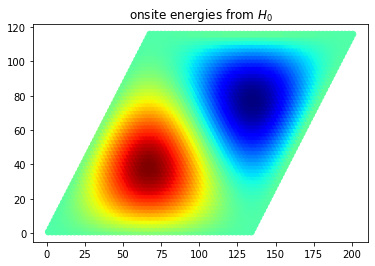

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.plot_onsite_energies("generate.pos", "generate.e")
plt.title(r"onsite energies from $H_0$")

If the calculation ran correctly and as a visual check for possible errors in the implementation, one can compare this real-space representation of $H_0$-induced onsite energies with the corresponding displacement-dependent maps from [this reference](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.89.205414).

## DOS

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/lanczosDOS_5/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 5", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 1"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .false.",
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .true.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818" # Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
]

inputStrings_lanczos = ["EnergyMin 0.0-1.0", # Minimum energy for plotting purposes
                        "EnergyMax 1.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps
inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log


[autoreload of PyToGrabnes failed: Traceback (most recent call last):
  File "/usr/local/lib/python3.8/dist-packages/IPython/extensions/autoreload.py", line 245, in check
    superreload(m, reload, self.old_objects)
  File "/usr/local/lib/python3.8/dist-packages/IPython/extensions/autoreload.py", line 394, in superreload
    module = reload(module)
  File "/usr/lib/python3.8/imp.py", line 314, in reload
    return importlib.reload(module)
  File "/usr/lib/python3.8/importlib/__init__.py", line 168, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'PyToGrabnes'
]


(0.0, 0.04)

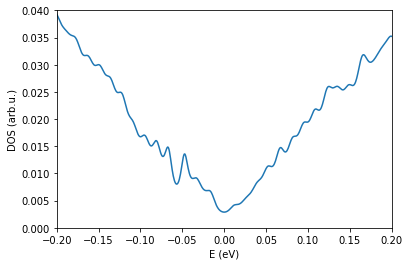

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
plt.xlim(-0.2,0.2)
plt.ylim(0.0,0.04)

### Magnetic field DOS

#### Zero disorder

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/lanczosDOS_5/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 5", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 1"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .false.",
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .true.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818" # Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
                    ]

inputStrings_lanczos = ["EnergyMin 0.0-1.0", # Minimum energy for plotting purposes
                        "EnergyMax 1.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps

inputStrings_mag = ["MagField.Integer 100" # Specify the integer that controls the magnetic field based on the simulation cell size.
                   # "MagField 50" # Specify the magnetic field in Tesla
                   # "MagField.InitialInteger 0 # Use this if you want to repeat the calculation for several magnetic fields. Useful for the calculation of Hofstadter butterfly diagrams or Wannier diagrams.
                   # "MagField.FinalInteger 1000
                   # "MagField.IntegerStep 2
                    ]

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham
                +inputStrings_mag)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

(0.0, 0.08)

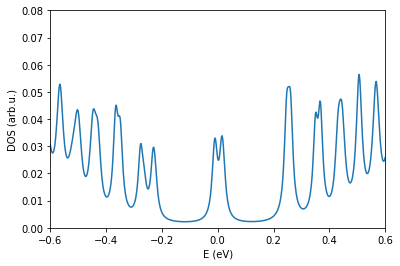

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
plt.xlim(-0.6,0.6)
plt.ylim(0.0,0.08)

#### Anderson disorder

To illustrate the modular nature of the code when building the Hamiltonian, we illustrate here what happens when adding Anderson disorder on top of the current G-hBN effective model Hamiltonian in presence of a magnetic field.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/lanczosDOS_5/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 5", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 1"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .false.",
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .true.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818" # Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
                    ]

inputStrings_lanczos = ["EnergyMin 0.0-1.0", # Minimum energy for plotting purposes
                        "EnergyMax 1.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps

inputStrings_mag = ["MagField.Integer 100" # Specify the integer that controls the magnetic field based on the simulation cell size.
                   # "MagField 50" # Specify the magnetic field in Tesla
                   # "MagField.InitialInteger 0 # Use this if you want to repeat the calculation for several magnetic fields. Useful for the calculation of Hofstadter butterfly diagrams or Wannier diagrams.
                   # "MagField.FinalInteger 1000
                   # "MagField.IntegerStep 2
                    ]

inputStrings_disorder = ["Anderson .true.",
                         "AndersonAmp 1.0",
                         ]

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham
                +inputStrings_mag
                +inputStrings_disorder)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

(0.0, 0.08)

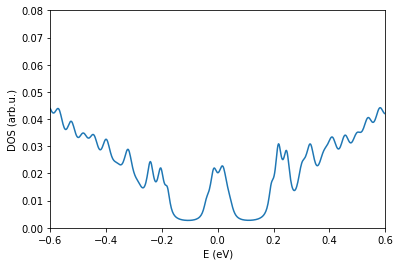

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
plt.xlim(-0.6,0.6)
plt.ylim(0.0,0.08)

If you correctly ran the code, the Landau levels become wider due to the presence of more localized disorder states in the tails around the center of the Landau level where the extended states reside. If you increase the disorder even further, the Landau levels cannot form anymore and a regular Anderson disorder insulator develops at all energies where all the states are localized.

# Future work

In case you would like to explore the capabilities of this code further (including transport observables, band-unfolding methods, etC), feel free to come talk to as well as check out the GRABNES documentation for further reference. This documentation is a work in progress, so for specific questions, let's have a chat or shoot me an email (lecontenicolas@gmail.com).